# Positioning the IQM-Based Mixed-Effects Harmonisation Framework

In this course, we will demonstrate an IQM-based harmonisation workflow using imaging-derived phenotypes (IDPs) from the [ON-Harmony](https://openneuro.org/datasets/ds004712/versions/2.0.1) dataset.

The framework implements a relatively lightweight and interpretable harmonisation strategy within a linear mixed-effects modelling framework. Rather than modelling scanner or site effects directly at the level of the imaging-derived phenotypes (IDPs), the approach uses image quality metrics (IQMs) to identify latent nuisance structure associated with scanner and acquisition variability. Additive and multiplicative correction is then applied selectively using mixed-effects regression models.

Conceptually, the framework can be viewed as a QC-informed harmonisation approach in which:

- scanner/site information is used to identify nuisance-related QC structure,
- biologically meaningful covariates are explicitly protected during QC selection,
- and correction is applied only when statistically justified.

Importantly, harmonisation is not imposed uniformly across all observations or phenotypes. Instead, the framework adaptively determines:

- which QC components are relevant for a given IDP,
- whether additive correction is appropriate,
- and whether multiplicative scaling sufficiently improves model fit to justify correction.

This differs from direct batch-normalisation approaches in which scanner/site correction is applied explicitly at the outcome level.

The framework is intentionally simple and transparent:

- modelling assumptions are linear,
- nuisance structure remains interpretable through QC variables,
- and harmonisation can be evaluated using standard mixed-effects diagnostics.

Such an approach may be particularly useful in:

- smaller clinical datasets,
- longitudinal studies,
- or settings with limited numbers of subjects per scanner/site, where highly flexible machine-learning approaches may be difficult to estimate robustly.

At the same time, this workflow represents only one point along a broader spectrum of IQM-based harmonisation strategies.

More advanced approaches, such as BARTharm, extend QC-informed harmonisation into substantially more flexible modelling frameworks. BARTharm uses Bayesian Additive Regression Trees (BART) to capture nonlinear relationships and higher-order interactions between image-quality structure, scanner effects, and biological variation. These approaches may provide a more robust representation of complex nuisance structure in large and heterogeneous datasets where scanner effects are unlikely to be adequately described by linear relationships alone.

Accordingly, the present workflow should be viewed as:

- a transparent and interpretable mixed-effects implementation,
- a useful pedagogical introduction to IQM-guided harmonisation,
- and a practical approach for smaller or clinically constrained datasets.

Together, these methods illustrate a broader shift away from direct batch-label correction toward harmonisation strategies that explicitly leverage image-quality information to characterize nuisance variation.

In [ ]:
# install packages if required
#%pip install numpy scipy pandas scikit-learn statsmodels matplotlib seaborn

## Inputs Required for the Code

The required files are stored in the `iqm_light_data` folder. This folder contains:

- **simulated_data.csv** — contains all IQMs and IDPs for each observation in the dataset. In this dataset we have one IDP to be harmonised and several QC metrics.

- **idp_list.csv** — contains the list of IDPs to be harmonised. These must match the corresponding column names in *simulated_data.csv*.

- **iqm_list.csv** — contains the list of IQMs to be used in the harmonisation workflow. These must match the corresponding column names in *simulated_data.csv*.

## Arguments to the Harmonisation Function

We will use the `iqm_harmonise` function from `iqm_harmonisation_light.py`. We recommend reviewing both the implementation and the inline documentation describing the function arguments before applying the workflow to your own datasets.

In [ ]:
# apply iqm harmonisation code
from scipy.stats import zscore
import pandas as pd

import importlib
import iqm_harmonisation_light

importlib.reload(iqm_harmonisation_light)

from iqm_harmonisation_light import iqm_harmonise

df = pd.read_csv("iqm_light_data/Simulated_data/simulated_data.csv")
idp_list = pd.read_csv("iqm_light_data/Simulated_data/idp_list.csv", header=None).iloc[:, 0].dropna().astype(str).str.strip().tolist()
iqm_list = pd.read_csv("iqm_light_data/Simulated_data/iqm_list.csv", header=None).iloc[:, 0].dropna().astype(str).str.strip().tolist()


data_out, qc_selection, add_detail_df, mult_detail_df, summary_df = iqm_harmonise(
    data=df,
    idp_list=idp_list,
    qc_list=iqm_list,
    preserve_covars=("Age",),
    adjust_covars=("Timepoint",),
    reverse_guard_covars=("Age",),
    categorical_covars=("Timepoint", "Batch"),
    batch_col="Batch",
    subject_col="Subject",
    age_source_col="Age",
    batch_source_col="Batch",
    age_col="Age",
    p_thr=0.05,
    apply_pca=True,
    iqm_variance=95,
    verbose_model_fits=False,
    enable_multiplicative=True
)

## Outputs

After running the IQM-based harmonisation workflow, several output files will be generated:

- *iqm_harmonised.csv*: contains the original and harmonised IDPs (`harmonised_<idp_name>`)
- *qc_selection_<additive/multiplicative>_details.csv*: contains statistical significance measures and summary information for QC selection
- *selected_<additive/multiplicative>_by_volume.csv*: contains the QC variables selected for each IDP

## Visualisation

Next, we will visualise the distribution of IDPs across batches using the outputs from *iqm_harmonised.csv*.

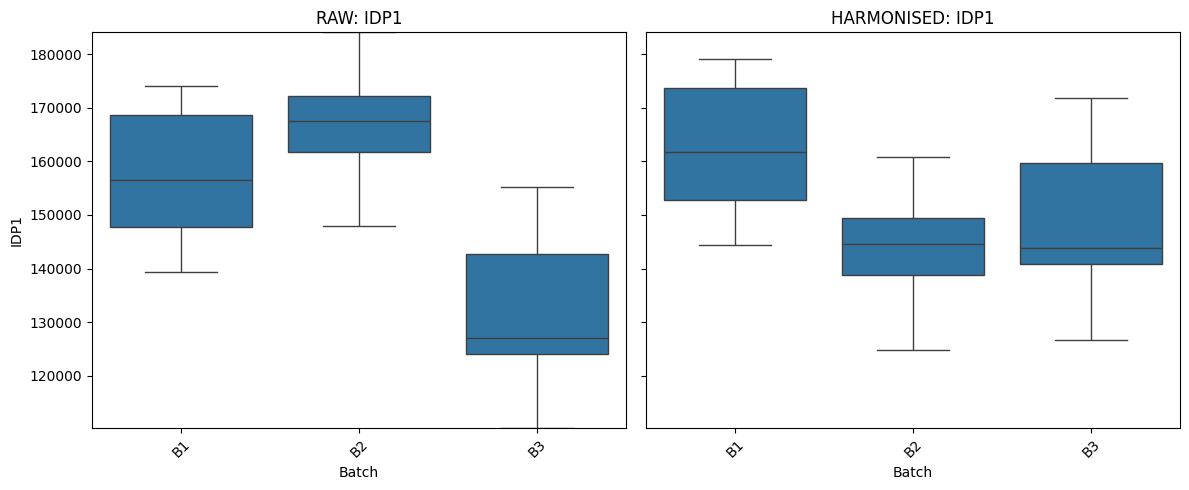

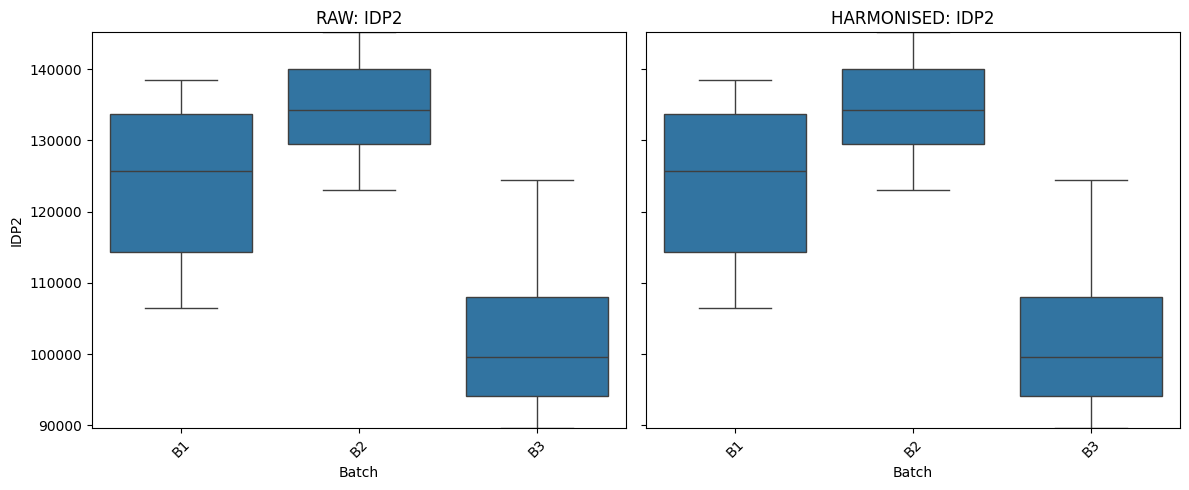

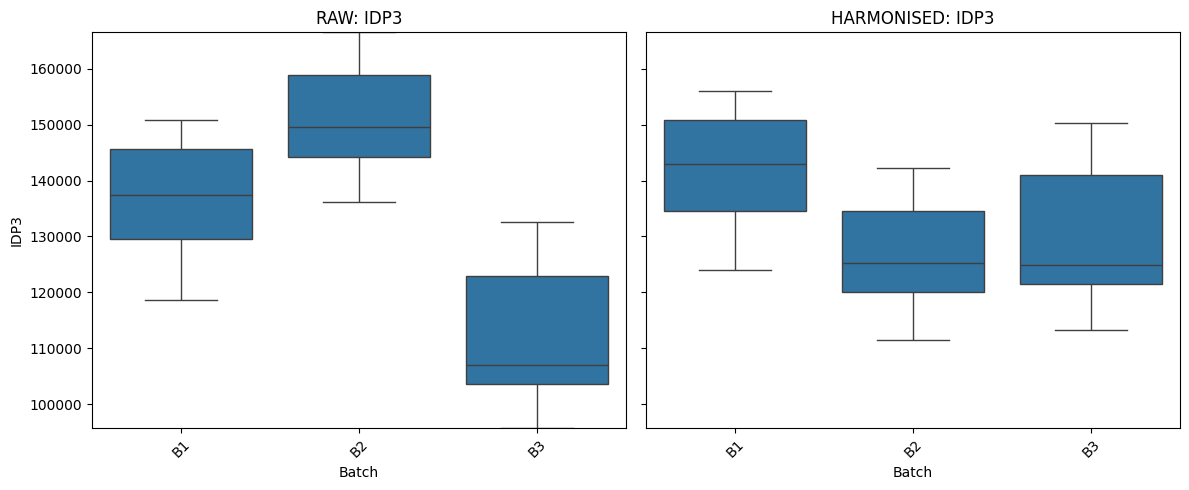

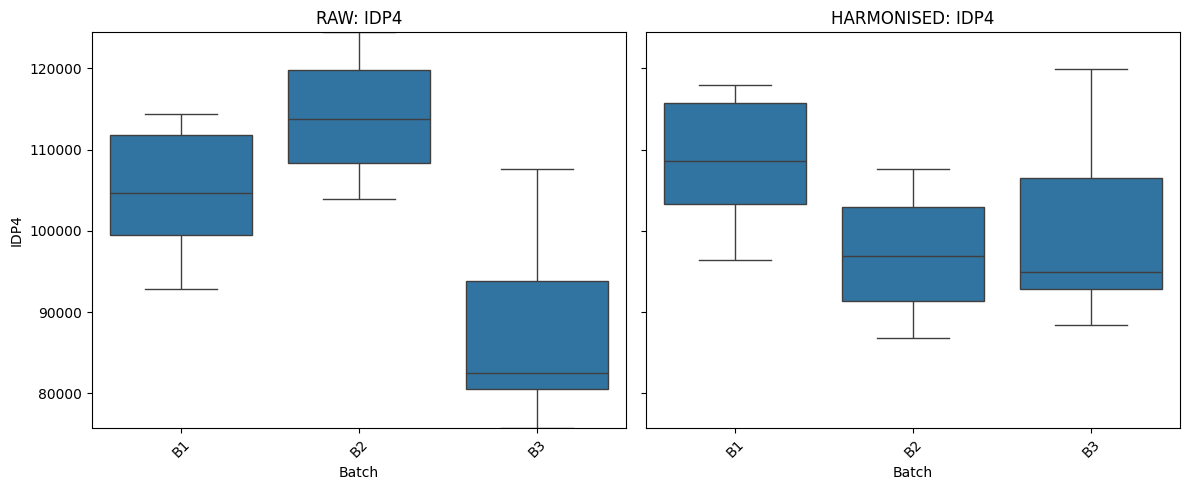

In [100]:
for idp in idp_list:
    raw_col = idp
    harm_col = f"harmonised_{idp}"

    fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

    ymin = min(data_out[raw_col].min(), data_out[harm_col].min())
    ymax = max(data_out[raw_col].max(), data_out[harm_col].max())

    sns.boxplot(data=data_out, x="Batch", y=raw_col, ax=axes[0])
    axes[0].set_title(f"RAW: {idp}")
    axes[0].tick_params(axis="x", rotation=45)
    axes[0].set_ylim(ymin, ymax)

    sns.boxplot(data=data_out, x="Batch", y=harm_col, ax=axes[1])
    axes[1].set_title(f"HARMONISED: {idp}")
    axes[1].tick_params(axis="x", rotation=45)
    axes[1].set_ylim(ymin, ymax)

    plt.tight_layout()
    plt.show()

## Conceptual Notes and Limitations

The current implementation still makes use of an explicit batch/scanner variable during the IQM selection stage. In this sense, the workflow remains partially batch-guided, similar to methods such as ComBat, which also rely on known batch labels during harmonisation.

However, unlike direct batch-correction methods, the scanner variable is not used directly to correct the imaging-derived phenotypes (IDPs). Instead, the framework first identifies image quality metrics (IQMs) that appear to capture scanner- or acquisition-related nuisance variation while avoiding IQMs that strongly encode biological or protected covariates. The selected IQMs are then used to guide harmonisation of the IDPs.

Conceptually, this makes the approach more indirect and relatively conservative compared with methods that directly regress out batch effects from all features. Correction is only driven by QC variables that satisfy the predefined statistical selection criteria, rather than by the scanner labels themselves.

One motivation for this strategy is that direct batch-correction approaches can sometimes increase the risk of over-correction, particularly in smaller or clinically heterogeneous datasets where scanner effects may be partially entangled with genuine biological variation. By constraining harmonisation through selected IQMs, the framework attempts to reduce removal of biologically meaningful signal while still mitigating nuisance variation.

More advanced IQM-driven approaches, such as BARTharm, move further away from explicit batch-guided correction by learning nuisance structure directly from image-quality patterns using more flexible nonlinear modelling strategies.

Regardless of the harmonisation method used, harmonised outputs should always be evaluated carefully using multiple complementary metrics and visualisations to assess both nuisance removal and preservation of biological signal.

In [49]:
# apply iqm harmonisation code
from scipy.stats import zscore
import pandas as pd

import importlib
import iqm_harmonisation_light

importlib.reload(iqm_harmonisation_light)

from iqm_harmonisation_light import iqm_harmonise

df = pd.read_csv("iqm_light_data/onharmony_reduced.csv")
idp_list = pd.read_csv("iqm_light_data/IDP_list.csv", header=None).iloc[:, 0].dropna().astype(str).str.strip().tolist()
iqm_list = pd.read_csv("iqm_light_data/IQM_list.csv", header=None).iloc[:, 0].dropna().astype(str).str.strip().tolist()


data_out, qc_selection, add_detail_df, mult_detail_df, summary_df = iqm_harmonise(
    data=df,
    idp_list=idp_list,
    qc_list=iqm_list,
    preserve_covars=("age",),
    adjust_covars=("timepoint",),
    reverse_guard_covars=("age",),
    categorical_covars=("timepoint", "scan_session"),
    batch_col="scan_session",
    subject_col="subject",
    age_source_col="age",
    batch_source_col="scan_session",
    age_col="age",
    iqm_variance=95,
    p_thr=0.05,
    apply_pca=True,
    verbose_model_fits=True,
)

=== IQM Harmonization (Flexible Version) ===
P-value threshold: 0.0500
Max QCs per volume: inf
PCA variance threshold: 95.0%
Apply PCA: True
Preserve covars: ['age']
Adjust covars: ['timepoint']
Categorical covars: ['timepoint', 'scan_session']
Reverse-guard covars: ['age']

Step 1: Preparing QC metrics...
  Removing 3 zero-variance QCs
  ['T1w_spacing_x', 'T1w_spacing_y', 'T1w_spacing_z']
  PCA input shape: (30, 16)
  Retaining PCs: 4 (96.19%)

Step 2: Selecting QCs for ADDITIVE correction...
  Criteria: batch-driven, not preserve-covariate-driven

=== Additive selection: T1_SIENAX_peripheral_GM_norm_vol ===

=== Additive selection: T1_SIENAX_CSF_norm_vol ===

=== Additive selection: T1_SIENAX_GM_norm_vol ===

=== Additive selection: T1_SIENAX_WM_norm_vol ===

=== Additive selection: T1_SIENAX_brain_norm_vol ===

=== Additive selection: T1_FIRST_left_hippocampus ===

=== Additive selection: T1_FIRST_right_hippocampus ===
  QCs selected: min=0, max=0, mean=0.0

Step 3: Selecting QCs fo

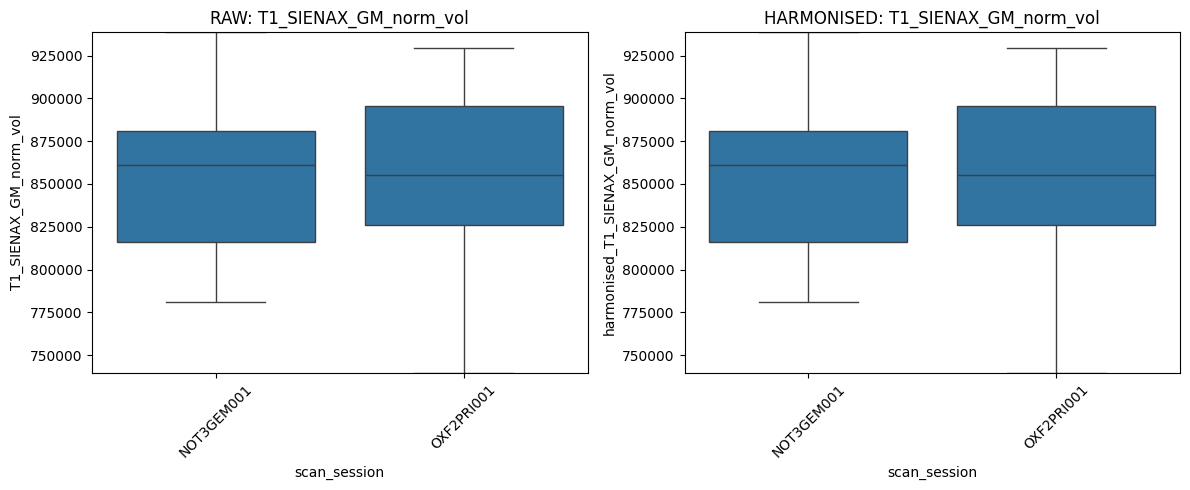

In [51]:
# plot IQM harmonised and raw volumes
import matplotlib.pyplot as plt
import seaborn as sns

idp = "T1_SIENAX_GM_norm_vol"

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# compute shared y-axis limits
ymin = min(
    data_out[idp].min(),
    data_out[f"harmonised_{idp}"].min()
)

ymax = max(
    data_out[idp].max(),
    data_out[f"harmonised_{idp}"].max()
)

sns.boxplot(
    data=data_out,
    x="scan_session",
    y=idp,
    ax=axes[0]
)
axes[0].set_title(f"RAW: {idp}")
axes[0].tick_params(axis='x', rotation=45)
axes[0].set_ylim(ymin, ymax)

sns.boxplot(
    data=data_out,
    x="scan_session",
    y=f"harmonised_{idp}",
    ax=axes[1]
)
axes[1].set_title(f"HARMONISED: {idp}")
axes[1].tick_params(axis='x', rotation=45)
axes[1].set_ylim(ymin, ymax)

plt.tight_layout()
plt.show()

/var/folders/49/vypjx8fn5dg65s46m9dfymb80000gq/T/ipykernel_76582/2717822088.py:82: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


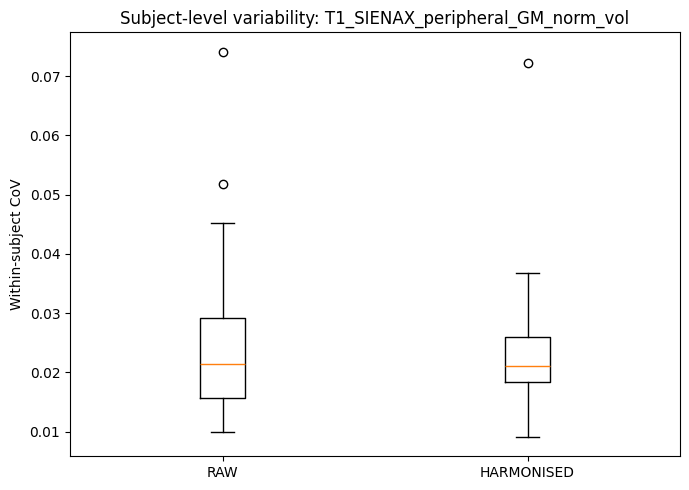

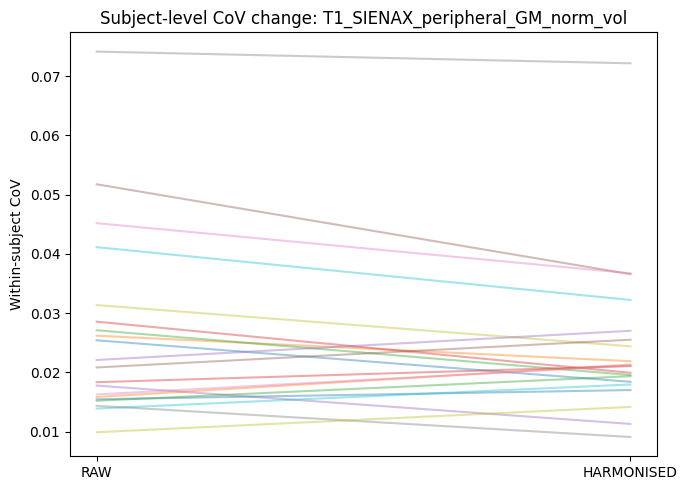

/var/folders/49/vypjx8fn5dg65s46m9dfymb80000gq/T/ipykernel_76582/2717822088.py:82: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


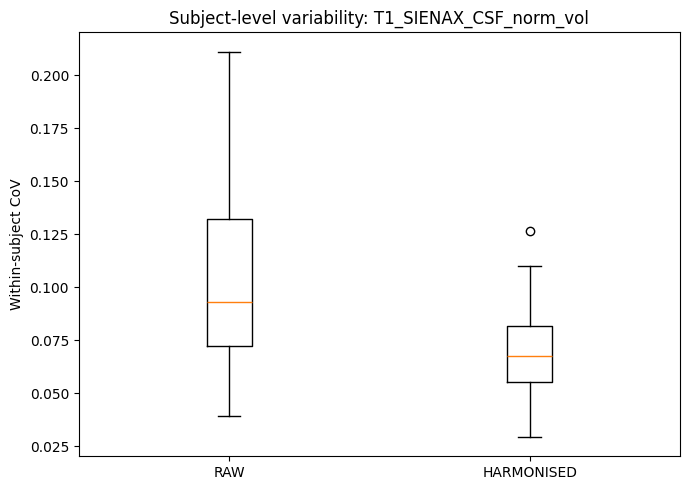

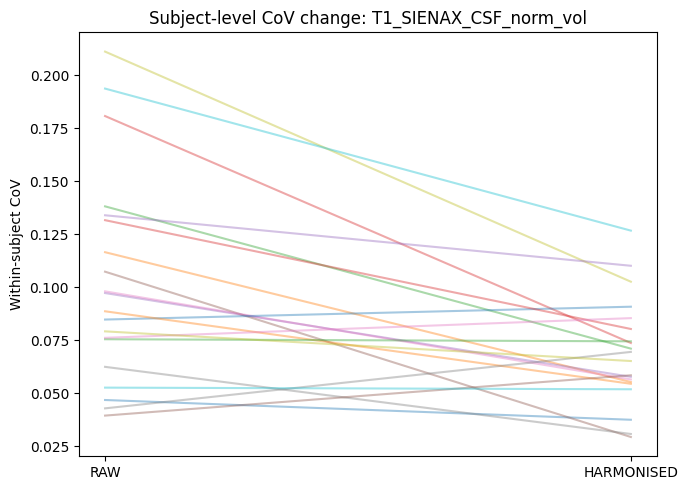

/var/folders/49/vypjx8fn5dg65s46m9dfymb80000gq/T/ipykernel_76582/2717822088.py:82: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


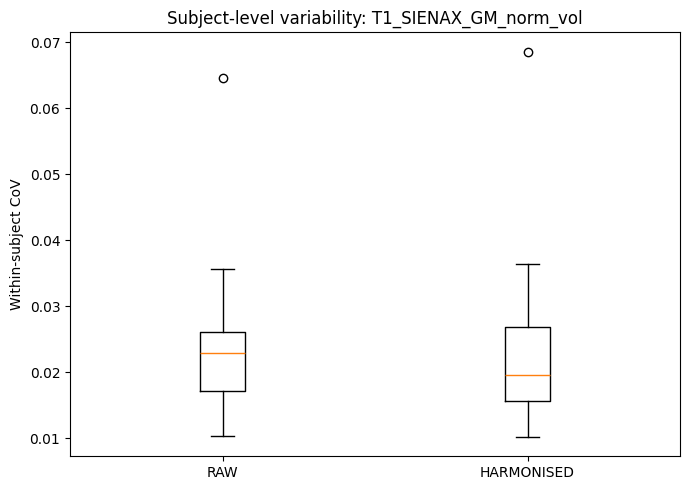

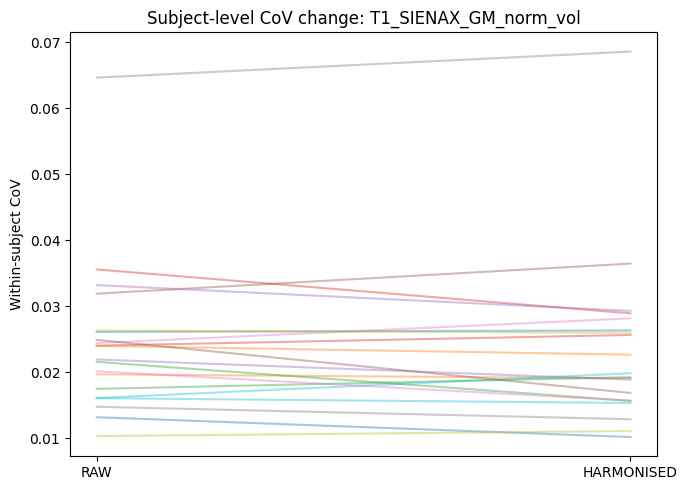

/var/folders/49/vypjx8fn5dg65s46m9dfymb80000gq/T/ipykernel_76582/2717822088.py:82: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


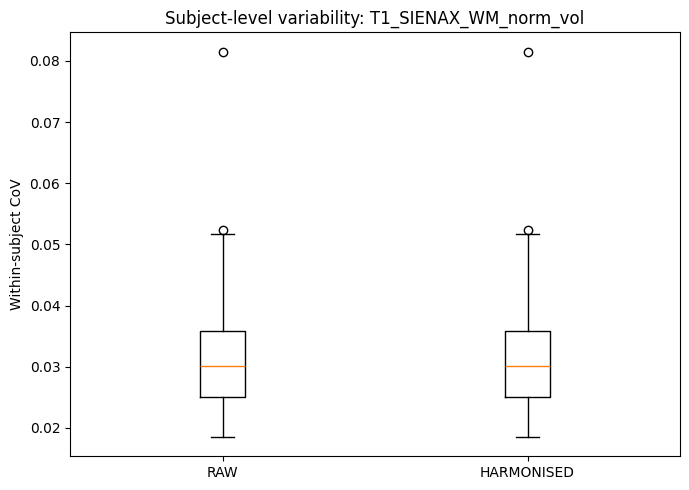

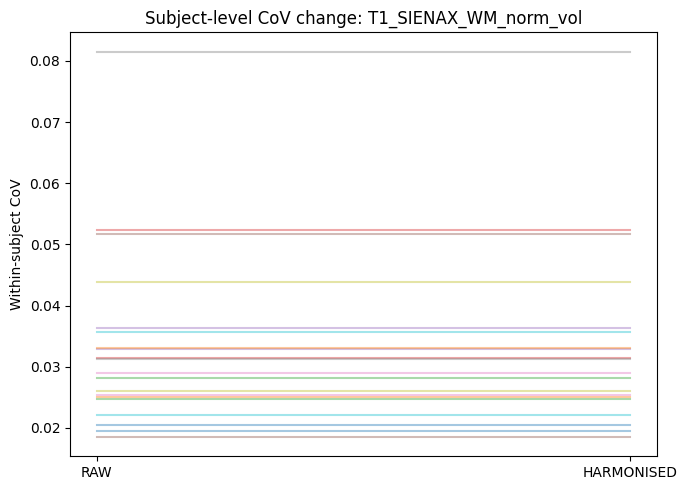

/var/folders/49/vypjx8fn5dg65s46m9dfymb80000gq/T/ipykernel_76582/2717822088.py:82: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


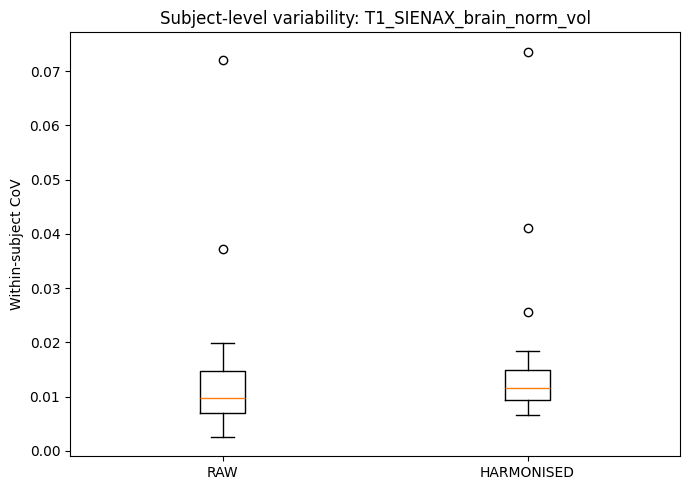

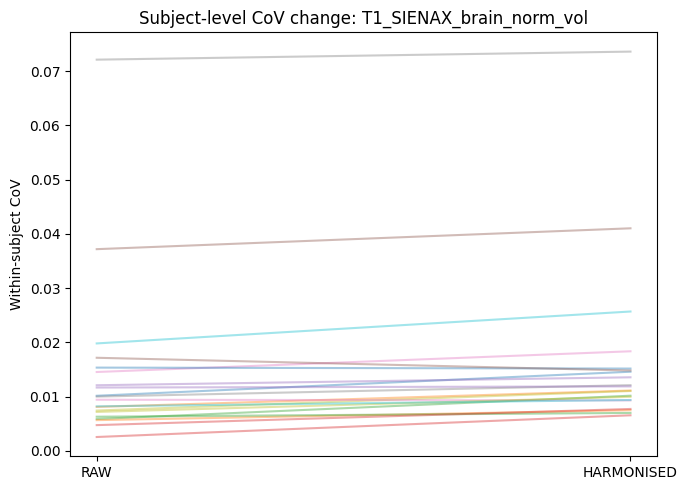

/var/folders/49/vypjx8fn5dg65s46m9dfymb80000gq/T/ipykernel_76582/2717822088.py:82: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


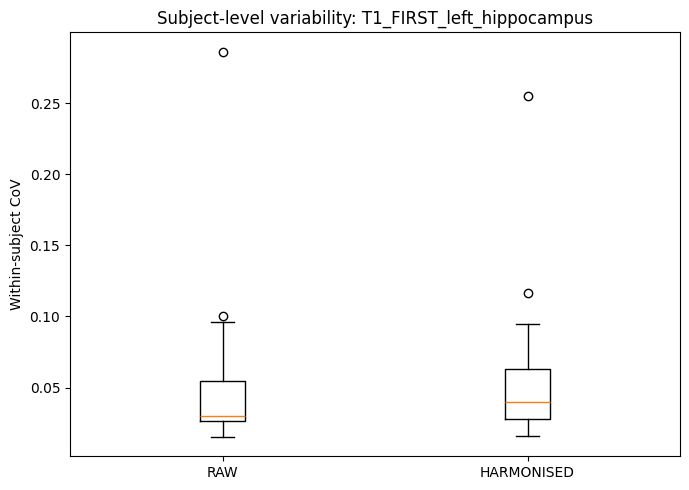

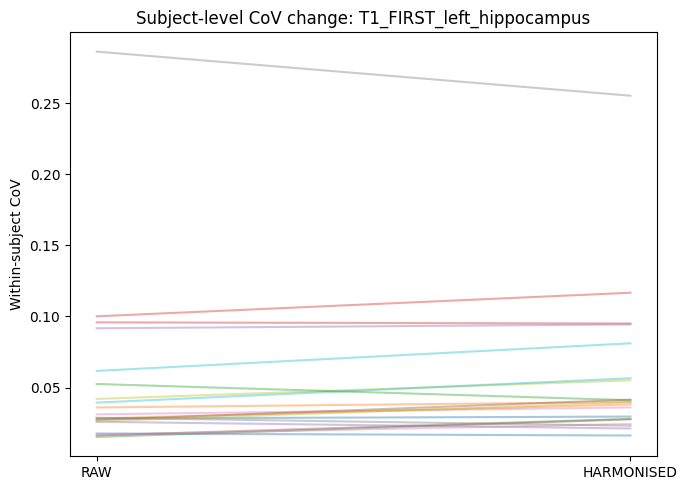

/var/folders/49/vypjx8fn5dg65s46m9dfymb80000gq/T/ipykernel_76582/2717822088.py:82: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


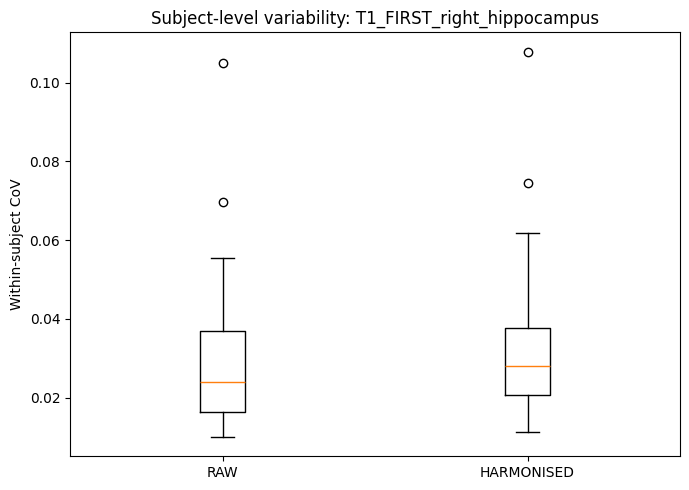

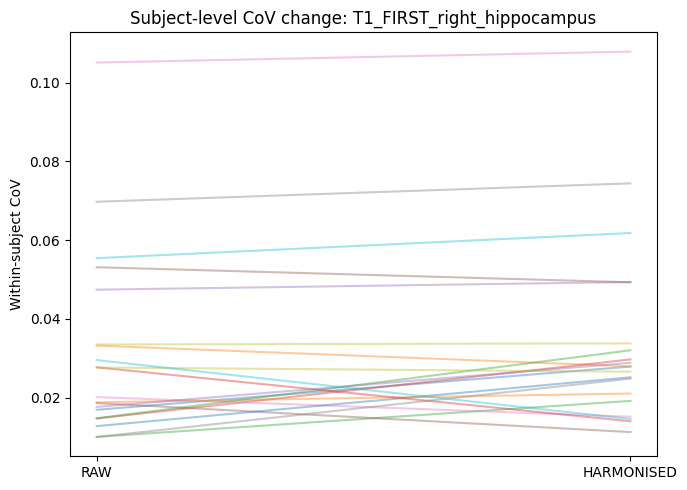

                                IDP  raw_mean_cov  harm_mean_cov  \
0  T1_SIENAX_peripheral_GM_norm_vol      0.026541       0.024341   
1            T1_SIENAX_CSF_norm_vol      0.102906       0.069178   
2             T1_SIENAX_GM_norm_vol      0.024311       0.023334   
3             T1_SIENAX_WM_norm_vol      0.033460       0.033460   
4          T1_SIENAX_brain_norm_vol      0.014269       0.016518   
5         T1_FIRST_left_hippocampus      0.053418       0.058080   
6        T1_FIRST_right_hippocampus      0.031849       0.034744   

   raw_median_cov  harm_median_cov  
0        0.021461         0.021107  
1        0.093025         0.067430  
2        0.022960         0.019542  
3        0.030157         0.030157  
4        0.009707         0.011494  
5        0.030042         0.039811  
6        0.023907         0.027941  


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# Subject-level longitudinal variability (CoV) before vs after
# ============================================================
#
# For each IDP:
#   - computes within-subject coefficient of variation (CoV)
#   - before harmonisation
#   - after harmonisation
#
# Requires:
#   data_out       : output dataframe from iqm_harmonise_flexible
#   idp_list       : list of raw IDP names
#
# Assumes:
#   subject column = "subject"
#
# ============================================================

subject_col = "subject"

cov_summary = []

for idp in idp_list:

    harm_idp = f"harmonised_{idp}"

    if harm_idp not in data_out.columns:
        print(f"Missing harmonised column: {harm_idp}")
        continue

    # --------------------------------------------------------
    # Compute subject-level CoV
    # --------------------------------------------------------
    rows = []

    for sid, tmp in data_out.groupby(subject_col):

        # RAW
        raw_vals = tmp[idp].dropna().to_numpy(dtype=float)

        if len(raw_vals) >= 2 and np.mean(raw_vals) != 0:
            raw_cov = np.std(raw_vals, ddof=1) / np.mean(raw_vals)
        else:
            raw_cov = np.nan

        # HARMONISED
        harm_vals = tmp[harm_idp].dropna().to_numpy(dtype=float)

        if len(harm_vals) >= 2 and np.mean(harm_vals) != 0:
            harm_cov = np.std(harm_vals, ddof=1) / np.mean(harm_vals)
        else:
            harm_cov = np.nan

        rows.append({
            "subject": sid,
            "raw_cov": raw_cov,
            "harm_cov": harm_cov,
        })

    cov_df = pd.DataFrame(rows)

    # --------------------------------------------------------
    # Save summary
    # --------------------------------------------------------
    cov_summary.append({
        "IDP": idp,
        "raw_mean_cov": cov_df["raw_cov"].mean(),
        "harm_mean_cov": cov_df["harm_cov"].mean(),
        "raw_median_cov": cov_df["raw_cov"].median(),
        "harm_median_cov": cov_df["harm_cov"].median(),
    })

    # --------------------------------------------------------
    # Plot
    # --------------------------------------------------------
    fig = plt.figure(figsize=(7, 5))

    plt.boxplot(
        [
            cov_df["raw_cov"].dropna(),
            cov_df["harm_cov"].dropna()
        ],
        labels=["RAW", "HARMONISED"]
    )

    plt.ylabel("Within-subject CoV")
    plt.title(f"Subject-level variability: {idp}")

    plt.tight_layout()
    plt.show()

    # --------------------------------------------------------
    # Optional paired-line plot
    # --------------------------------------------------------
    fig = plt.figure(figsize=(7, 5))

    for _, r in cov_df.iterrows():
        plt.plot(
            [1, 2],
            [r["raw_cov"], r["harm_cov"]],
            alpha=0.4
        )

    plt.xticks([1, 2], ["RAW", "HARMONISED"])
    plt.ylabel("Within-subject CoV")
    plt.title(f"Subject-level CoV change: {idp}")

    plt.tight_layout()
    plt.show()

# ============================================================
# Summary table
# ============================================================

cov_summary_df = pd.DataFrame(cov_summary)

print(cov_summary_df)

# Optional save
cov_summary_df.to_csv("subject_level_cov_summary.csv", index=False)